In [87]:
import joblib
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid", context="notebook")

# Load model + feature names
model, feature_columns = joblib.load("models/nhl_rookie_predictor_xgb_ppg.pkl")


In [88]:

# Example new player
new_player = {
    "gp_amateur": 41,
    "ppg_amateur": 1.585,
    'age_at_rookie_start': 19.66, 
    'weight': 201, 
    'height': 74,
    "ahl": 0,
    "liiga": 0,
    "ncaa": 1,
    "ohl": 0,
    "qmjhl": 0,
    "shl": 0,
    "whl": 0,
    "khl": 0,
    "nl": 0,
    "ushl": 0
}

# Ensure correct order
df_input = pd.DataFrame([new_player])[feature_columns]

# Predict
prediction = model.predict(df_input)
print(f"Predicted NHL ppg: {prediction[0]:.2f}")

Predicted NHL ppg: 0.43


In [89]:
# Load test data
test_data = pd.read_csv("data/processed/amateur_to_rookie_with_bio.csv")
test_data = test_data[test_data['gp_nhl'] >= 15]
test_data = test_data[test_data['gp_amateur'] >= 15]

# Create league dummies (must match training)
league_hardcode = pd.get_dummies(test_data['league_amateur'])
test_data = pd.concat([test_data, league_hardcode], axis=1)

# Fill missing numeric values (same as training)
test_data['age_at_rookie_start'] = test_data['age_at_rookie_start'].fillna(test_data['age_at_rookie_start'].median())
test_data['weight'] = test_data['weight'].fillna(test_data['weight'].median())
test_data['height'] = test_data['height'].fillna(test_data['height'].median())

# Now separate features & target
X_test = test_data[feature_columns] 
y_actual_ppg = test_data["ppg_nhl"]    



In [90]:
y_pred_ppg = model.predict(X_test)


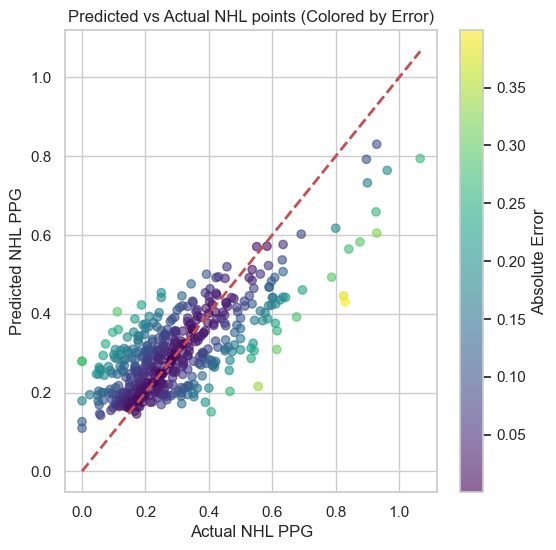

In [91]:
import numpy as np

errors = np.abs(y_actual_ppg - y_pred_ppg)

plt.figure(figsize=(6,6))
plt.scatter(y_actual_ppg, y_pred_ppg, c=errors, cmap='viridis', alpha=0.6)
plt.plot([y_actual_ppg.min(), y_actual_ppg.max()],
         [y_actual_ppg.min(), y_actual_ppg.max()],
         'r--', lw=2)
plt.xlabel("Actual NHL PPG")
plt.ylabel("Predicted NHL PPG")
plt.title("Predicted vs Actual NHL points (Colored by Error)")
plt.colorbar(label="Absolute Error")
plt.show()


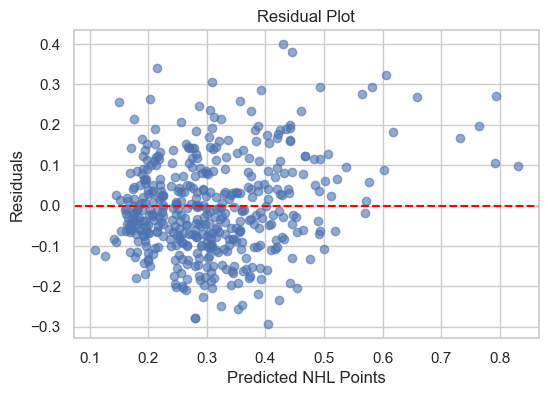

In [92]:
residuals = y_actual_ppg - y_pred_ppg
plt.figure(figsize=(6,4))
plt.scatter(y_pred_ppg, residuals, alpha=0.6)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel("Predicted NHL Points")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.show()


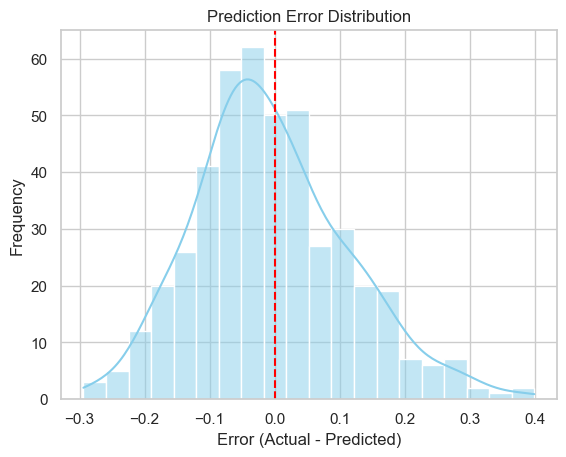

In [93]:
sns.histplot(residuals, kde=True, bins=20, color="skyblue")
plt.axvline(0, color='red', linestyle='--')
plt.title("Prediction Error Distribution")
plt.xlabel("Error (Actual - Predicted)")
plt.ylabel("Frequency")
plt.show()


In [94]:

import numpy as np
from scipy import stats

# Select only numeric features
numeric_features = test_data[feature_columns].select_dtypes(include=np.number)

# Compute z-scores (ignoring NaNs)
z_scores = np.abs(stats.zscore(numeric_features, nan_policy='omit'))

# Find rows where any numeric feature is an outlier (|z| > 3)
outlier_rows = np.where(z_scores > 3)[0]

# Get unique row indices
unique_outlier_rows = np.unique(outlier_rows)

print(unique_outlier_rows)      
print(test_data.index.min(), test_data.index.max())


# Subset the original test dataset to include only outliers
outliers_with_stats = test_data.iloc[np.unique(outlier_rows)]

# Optional: count the number of outlier rows
print("Number of outlier rows:", len(outliers_with_stats))

# Display the outlier rows with all features
print(outliers_with_stats)

# Optional: save to CSV
outliers_with_stats.to_csv("data/outlier data for study/outliers_with_stats.csv", index=False)
print("Saved outliers with stats to outliers_with_stats.csv")


[ 92  97 130 198 246 272 367 426]
1 975
Number of outlier rows: 8
                       name season_amateur        team_amateur league_amateur  \
212    Connor Bedard (C/LW)      2022-2023         Regina Pats            whl   
219   Connor McDavid (C/LW)      2014-2015         Erie Otters            ohl   
294  Elias Pettersson (C/W)      2017-2018     Växjö Lakers HC            shl   
453  Jonathan Drouin (LW/C)      2013-2014  Halifax Mooseheads          qmjhl   
561       Louis Crevier (D)      2022-2023    Rockford IceHogs            ahl   
611       Matt Rempe (RW/C)      2022-2023  Hartford Wolf Pack            ahl   
796        Ryan Johnson (D)      2022-2023  Univ. of Minnesota           ncaa   
936     Viktor Svedberg (D)      2014-2015    Rockford IceHogs            ahl   

     gp_amateur  goals_amateur  assists_amateur  points_amateur  ppg_amateur  \
212          57             71               72             143     2.508772   
219          47             44              

In [95]:
import pandas as pd

# Load the outliers CSV
outliers_df = pd.read_csv("outliers_with_stats.csv")

# Make sure 'name' is the common key
actual_vs_pred = outliers_df.merge(
    pd.DataFrame({
        'name': test_data['name'],
        'actual': y_actual_ppg,       # your actual target
        'predicted': y_pred_ppg     # model predictions
    }),
    on='name',
    how='left'
)

actual_vs_pred.to_csv("data/outlier data for study/outliers_actual_vs_pred.csv", index=False)
